In [12]:
import neurokit2 as nk
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [13]:
wesad_data = pd.read_csv("../Data/wesad_eda/filtered_eda_signals.csv")
wesad_data.iloc[0:6,0]

0    0.000000
1    0.073305
2    0.116746
3    0.083819
4    0.062718
5    0.079352
Name: S15_EDA, dtype: float64

In [14]:
eda_signals, info = nk.eda_process(wesad_data.iloc[:, 0], sampling_rate=4)

# Extract the processed components
phasic = eda_signals["EDA_Phasic"]
tonic = eda_signals["EDA_Tonic"]
cleaned = eda_signals["EDA_Clean"]

/home/sj/.local/lib/python3.12/site-packages/neurokit2/eda/eda_clean.py:102: NeuroKitWarning: EDA signal is sampled at very low frequency. Skipping filtering.
  warn(


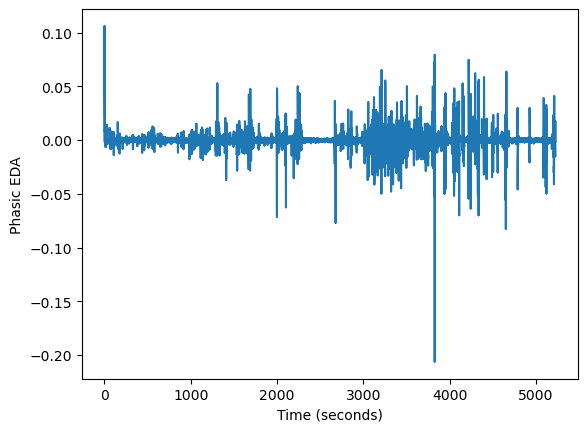

In [15]:
time = np.arange(len(phasic)) / 4

plt.plot(time, phasic, label='phasic component')
plt.xlabel('Time (seconds)')
plt.ylabel('Phasic EDA')
plt.show()

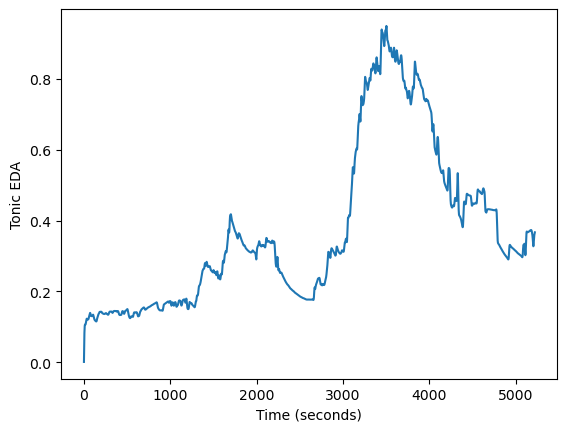

In [16]:
time = np.arange(len(tonic)) / 4

plt.plot(time, tonic)
plt.xlabel('Time (seconds)')
plt.ylabel('Tonic EDA')
plt.show()

Grab a dictionary of every participant ID then follow the dataframe label logic to extract directly their EDA column and Label column then apply the CVXeda decomposition and store their tonic and phasic components in new dataframes with their respective participant ID.

In [17]:
tonic_signals = []
phasic_signals = []

# Dictionary of participant IDs
subject_ids = list(dict.fromkeys([col.split('_')[0] for col in wesad_data.columns]))

for subject_id in subject_ids:
    eda_col = f'{subject_id}_EDA'
    label_col = f'{subject_id}_Label'

    eda_signal = wesad_data[eda_col]
    labels = wesad_data[label_col]

    # Apply cvxEDA decomposition
    eda_signals, info = nk.eda_process(eda_signal, sampling_rate=8)    
        
    # Build the structured DataFrame for the current participant
    tonic_dataframe = pd.DataFrame({
            f'{subject_id}_Tonic': eda_signals['EDA_Tonic'],
            f'{subject_id}_Label': labels
        })

    phasic_dataframe = pd.DataFrame({
                    f'{subject_id}_Phasic': eda_signals['EDA_Phasic'],
                    f'{subject_id}_Label': labels
                })
        
    tonic_signals.append(tonic_dataframe)
    phasic_signals.append(phasic_dataframe)
    

        


# Combine all subject results
#final_filtered_data = pd.concat(filtered_signals, axis=1)

In [18]:
tonic_csv = pd.concat(tonic_signals, axis=1)
tonic_csv.head()

,S15_Tonic,S15_Label,S7_Tonic,S7_Label,S3_Tonic,S3_Label,S2_Tonic,S2_Label,S14_Tonic,S14_Label,...,S4_Tonic,S4_Label,S13_Tonic,S13_Label,S5_Tonic,S5_Label,S9_Tonic,S9_Label,S6_Tonic,S6_Label
0,0.003759,0.0,-0.008207,0.0,0.030668,0.0,0.131371,0.0,0.029557,0.0,...,0.047935,0.0,0.011682,0.0,0.002346,0.0,0.059078,0.0,0.041740,0
1,0.006247,0.0,0.011484,0.0,0.038976,0.0,0.145760,0.0,0.035674,0.0,...,0.051862,0.0,0.026645,0.0,0.004534,0.0,0.064246,0.0,0.048556,0
2,0.008738,0.0,0.031135,0.0,0.047270,0.0,0.160146,0.0,0.041805,0.0,...,0.055849,0.0,0.041600,0.0,0.006744,0.0,0.069415,0.0,0.055361,0
3,0.011228,0.0,0.050718,0.0,0.055537,0.0,0.174509,0.0,0.047941,0.0,...,0.059892,0.0,0.056527,0.0,0.008973,0.0,0.074577,0.0,0.062145,0
4,0.013713,0.0,0.070205,0.0,0.063767,0.0,0.188830,0.0,0.054075,0.0,...,0.063989,0.0,0.071406,0.0,0.011220,0.0,0.079725,0.0,0.068901,0


In [19]:
phasic_csv = pd.concat(phasic_signals, axis=1)
phasic_csv.head()

,S15_Phasic,S15_Label,S7_Phasic,S7_Label,S3_Phasic,S3_Label,S2_Phasic,S2_Label,S14_Phasic,S14_Label,...,S4_Phasic,S4_Label,S13_Phasic,S13_Label,S5_Phasic,S5_Label,S9_Phasic,S9_Label,S6_Phasic,S6_Label
0,-0.003760,0.0,0.008203,0.0,-0.014625,0.0,-0.033904,0.0,-0.017644,0.0,...,-0.047922,0.0,-0.011687,0.0,-0.002346,0.0,-0.021322,0.0,-0.007875,0
1,0.068880,0.0,0.484507,0.0,0.143000,0.0,0.355715,0.0,0.144158,0.0,...,-0.020020,0.0,0.348690,0.0,0.062237,0.0,0.082505,0.0,0.154848,0
2,0.105374,0.0,0.808198,0.0,0.267717,0.0,0.596687,0.0,0.229818,0.0,...,-0.002967,0.0,0.575054,0.0,0.100097,0.0,0.151363,0.0,0.262361,0
3,0.074693,0.0,0.689895,0.0,0.244299,0.0,0.455138,0.0,0.148142,0.0,...,-0.014703,0.0,0.464230,0.0,0.078404,0.0,0.125096,0.0,0.217390,0
4,0.048252,0.0,0.535750,0.0,0.192267,0.0,0.300977,0.0,0.065325,0.0,...,-0.028790,0.0,0.348016,0.0,0.051368,0.0,0.091564,0.0,0.161552,0


In [ ]:
tonic_csv.to_csv("../Data/wesad_eda/tonic_signal_nk.csv", index=False)
phasic_csv.to_csv("../Data/wesad_eda/phasic_signal_nk.csv", index=False)
